### Dylan Renard
### Applied Machine Learning JHU
### Homework 3
### Professor Alhassan
### Feb 6th, 2026


## HW Assignment 3: Applied Machine Learning @JHU

#### Q1. [10 pts] Due to the severity of this  real-world  crisis, what information  would be the most important  to "machine  learn"?  Can it be learned?  (Note that  this is asking  you to define the big-picture  question  that we want to answer  from this dataset.  This is not asking  you to conjecture which feature is going  to turn out being  important.) 

The most important information to “machine learn” from this dataset is whether population-level demographic and contextual factors can be used to distinguish relatively high suicide-rate situations from lower ones. Because the data are aggregated by country, year, sex, and age group, the appropriate learning objective is not individual prediction, but rather identifying which population contexts tend to be associated with elevated suicide rates. Framed this way, the dataset can support a meaningful classification task that helps highlight patterns across regions and demographic groups, which is valuable for public-health monitoring and hypothesis generation.

This information can be learned in a limited but useful sense. A machine learning model can capture statistical associations and predictive signals that separate higher-rate from lower-rate cases within the dataset. However, these learned patterns should not be interpreted as causal relationships or individual-level risk predictions. Important contributors to suicide, such as personal mental health history or access to care, are not present in the data, so the model’s role is best understood as identifying population-level trends rather than explaining underlying causes.


#### Q2. [10 pts] Explain  in detail  how one should  set up the problem. Would  it be a regression  or a classification  problem?  Is any unsupervised  approach,  to look for patterns,  worthwhile? 

This problem can be approached using both supervised and unsupervised learning, and the choice of method depends on the type of insight being sought. A supervised regression formulation allows the continuous outcome suicides/100k pop to be modeled as a function of demographic and socioeconomic indicators such as year, sex, age group, generation, population size, GDP per capita, and human development index. This approach focuses on learning relationships between public health indicators and suicide rates while minimizing reliance on country identity, which helps reduce the risk of encoding location specific biases into the model.

An unsupervised approach, such as clustering, can also be useful for exploratory analysis by examining whether countries or demographic groups naturally group together based on shared characteristics. However, clustering that includes country identity risks reinforcing existing regional or reporting biases rather than revealing transferable public health patterns. For this reason, unsupervised methods are best used cautiously and primarily as an exploratory tool, while regression based modeling provides a more controlled and interpretable framework for analyzing how public health indicators are associated with suicide rates. As discussed in Chapter 1 of the course textbook, selecting an appropriate learning paradigm requires balancing predictive goals with interpretability and bias considerations (Raschka, 2022).

#### Q3. [20 pts] What  should  be the dependent  variable?
The dependent variable should be the continuous suicide rate per 100,000 population (suicides/100k pop). This variable provides a normalized measure of suicide incidence that allows meaningful comparison across countries, years, and demographic groups with very different population sizes. Using the rate rather than raw suicide counts ensures that the outcome reflects relative risk at the population level, which is appropriate given the public health focus of the dataset. Raw suicide counts are not used as the dependent variable because they scale directly with population size and would confound underlying risk with country size effects.

Selecting a continuous dependent variable supports a regression based formulation that preserves the full variability in the data and avoids imposing arbitrary thresholds or categories. This choice is especially appropriate for exploratory and analytical goals, as it allows the model to capture gradual differences in suicide rates across contexts and supports downstream analyses such as pattern discovery and correlation analysis. Because the data are aggregated and ecological in nature, the dependent variable should be interpreted strictly at the population level rather than as an individual level risk measure.

#### Q4. [20 pts] Find  some strong correlations  between  the independent  variables  and the dependent  variable  you decided  and use them to rank the independent  variables. 

Remaining object columns that are NOT expected to be categorical: []


sex_male                      0.391496
age_5-14 years               -0.286660
age_75+ years                 0.262910
generation_Millenials        -0.202139
generation_G.I. Generation    0.194180
generation_Silent             0.160926
generation_Generation Z      -0.151645
age_55-74 years               0.078819
generation_Generation X      -0.065182
age_35-54 years               0.050304
log_population                0.049284
year                         -0.039037
HDI for year                  0.037894
 gdp_for_year ($)             0.025240
age_25-34 years              -0.014851
gdp_per_capita ($)            0.001785
dtype: float64

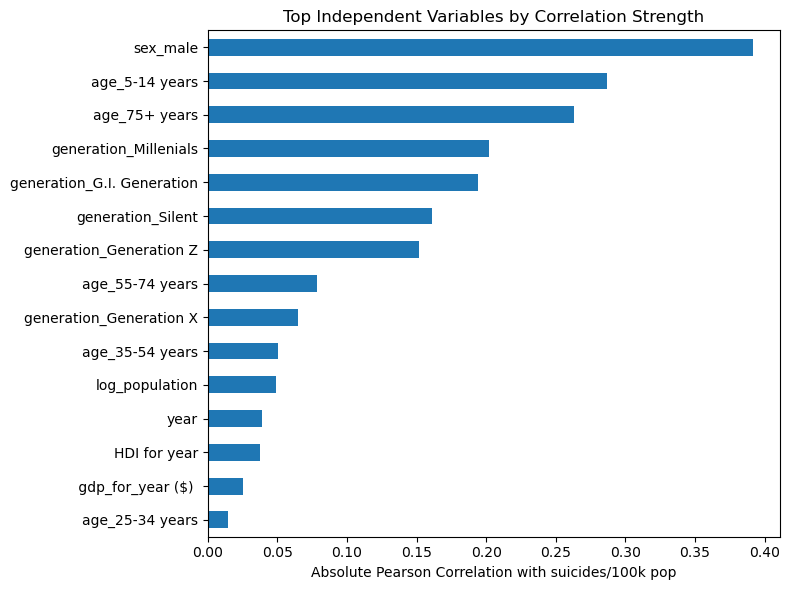

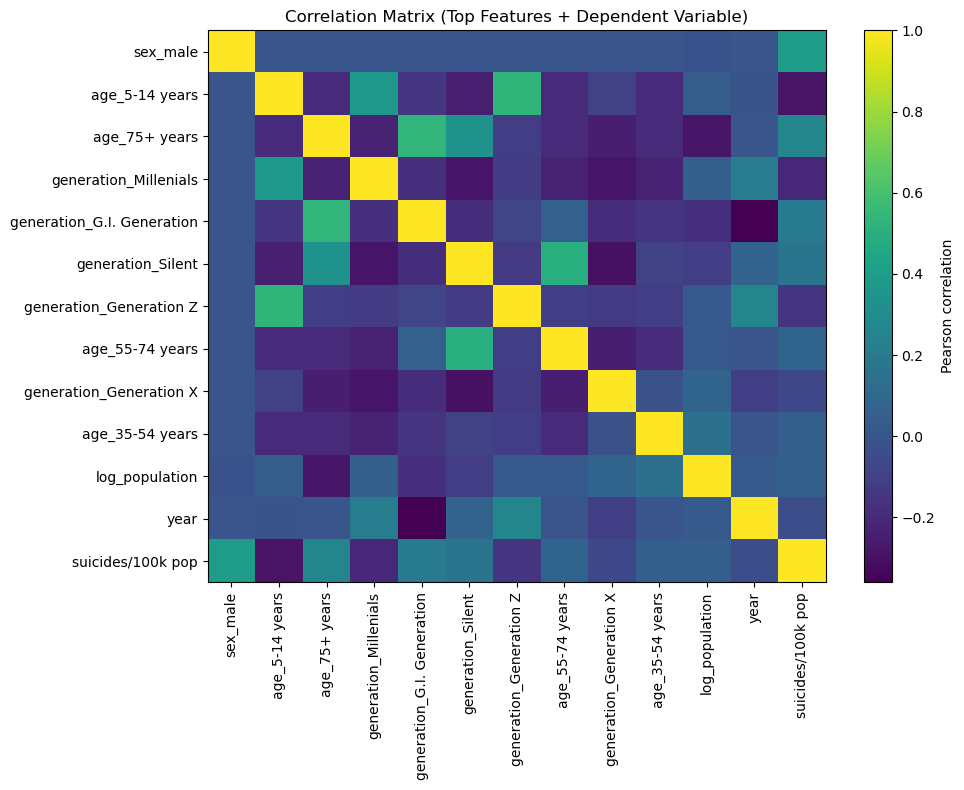

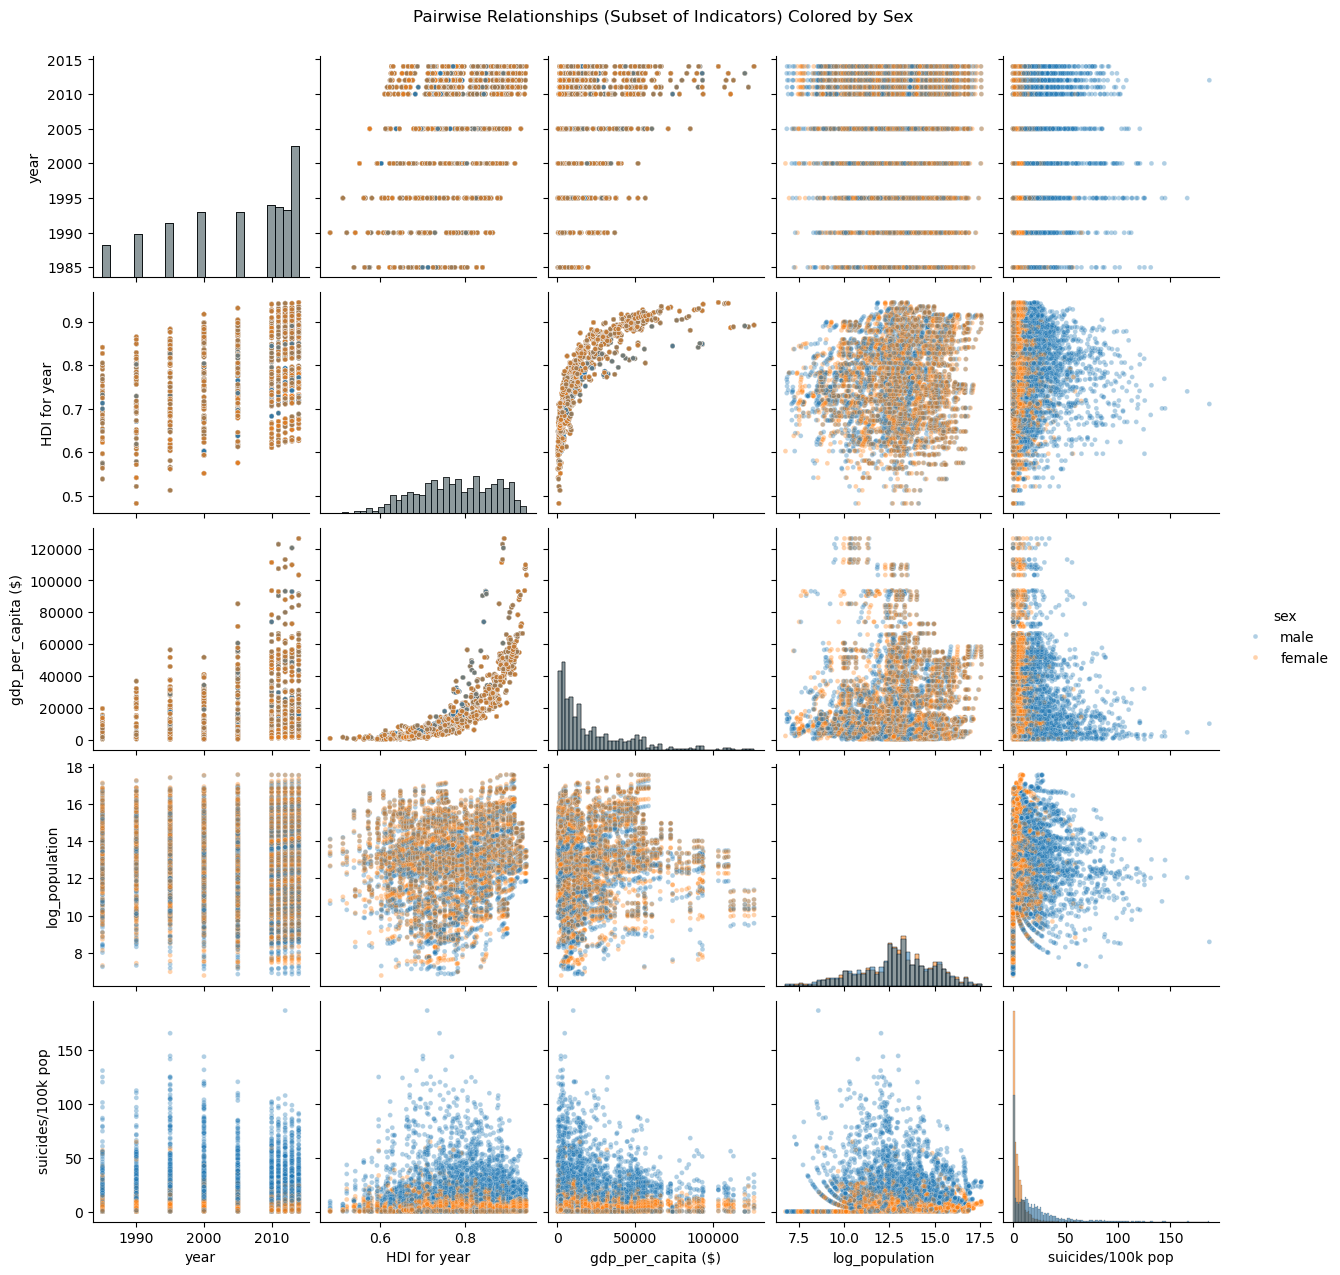

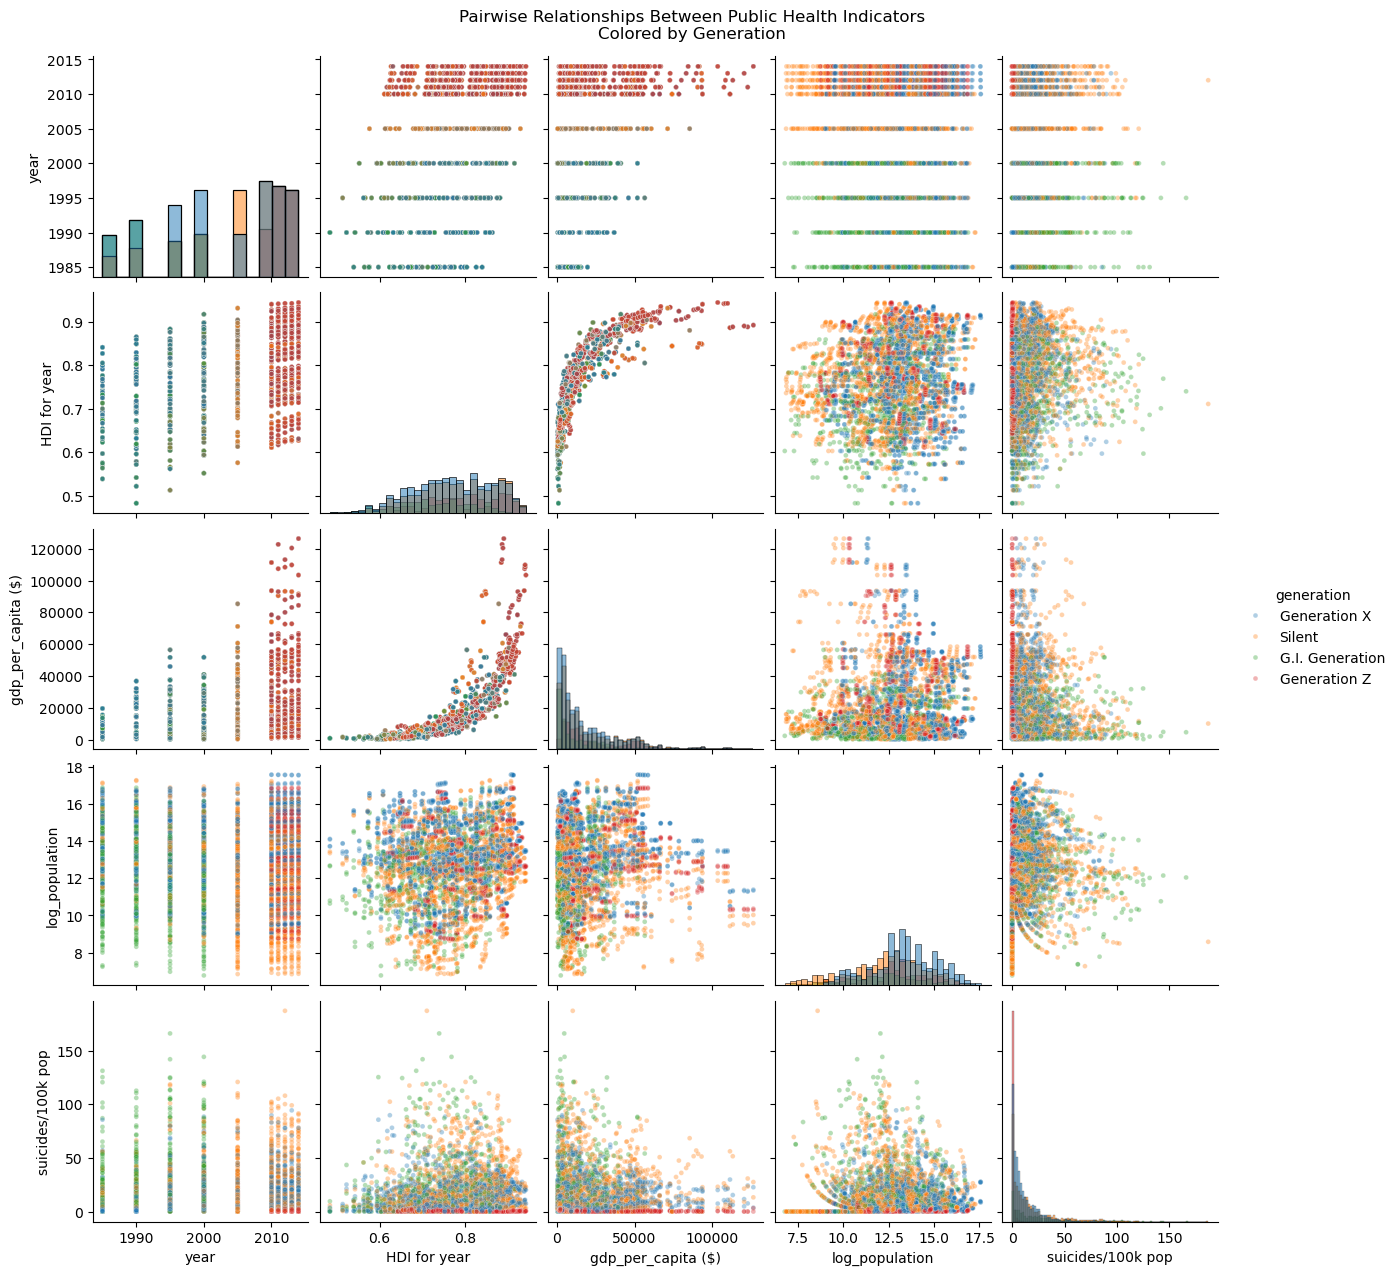

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ===============================================================
# Q4: Rank independent variables by association with suicide rate
# ===============================================================
# Context for this assignment:
# - Dependent variable: suicides/100k pop (population-level suicide rate)
# - We avoid identity-based predictors (country, country-year) because they
#   act like row identifiers and can bake in regional/reporting bias.
# - We avoid outcome-adjacent variables (suicides_no) because they leak the target.
# - We retain demographic strata (sex, age, generation) because these are
#   transferable population descriptors and are appropriate for encoding.
# - We keep population context but log-transform it to capture scale effects
#   without letting raw population dominate correlations.

# ----------------------------
# Load dataset
# ----------------------------
df = pd.read_csv("master.csv")
target_col = "suicides/100k pop"

# ----------------------------
# 1) Clean comma-formatted numeric strings (data hygiene)
# ----------------------------
# In this dataset, some numeric fields may be stored as strings with commas
# (e.g., "2,156,624,900"). Correlation and log transforms require true numeric types.
# We attempt to convert any object column that becomes numeric after comma removal,
# while leaving truly categorical fields untouched.
for col in df.select_dtypes(include="object").columns:
    # Explicitly keep categorical/identifier columns as strings
    if col in ["country", "sex", "age", "generation", "country-year"]:
        continue

    # Remove commas and attempt numeric conversion
    cleaned = df[col].astype(str).str.replace(",", "", regex=False)
    numeric_try = pd.to_numeric(cleaned, errors="coerce")

    # If conversion yields any numeric values, adopt the numeric column (NaN otherwise)
    if numeric_try.notna().sum() > 0:
        df[col] = numeric_try

# Sanity check: if any remaining object columns are not expected categorical fields,
# they can cause downstream numeric operations to fail (corr, median impute, etc.).
remaining_obj = [
    c for c in df.select_dtypes(include="object").columns
    if c not in ["country", "sex", "age", "generation", "country-year"]
]
print("Remaining object columns that are NOT expected to be categorical:", remaining_obj)

# ----------------------------
# 2) Build Q4 analysis dataset (remove identifiers + leakage)
# ----------------------------
# - country and country-year: identifiers, not transferable predictors
# - suicides_no: outcome-adjacent leakage variable (strongly tied to the target)
drop_cols = ["country", "country-year", "suicides_no"]
df_q4 = df.drop(columns=[c for c in drop_cols if c in df.columns])

# Ensure the dependent variable is numeric and remove rows with missing target
df_q4[target_col] = pd.to_numeric(df_q4[target_col], errors="coerce")
df_q4 = df_q4.dropna(subset=[target_col])

# ----------------------------
# 3) Include population context safely (log transform)
# ----------------------------
# Population size provides important context (e.g., stability of rates in large vs small
# populations). However, it is mathematically related to the rate denominator, so we
# use log(population) to capture scale without letting raw counts dominate.
if "population" in df_q4.columns:
    df_q4["population"] = pd.to_numeric(df_q4["population"], errors="coerce")
    df_q4 = df_q4.dropna(subset=["population"])
    df_q4["log_population"] = np.log(df_q4["population"])
    df_q4 = df_q4.drop(columns=["population"])

# ----------------------------
# 4) Separate target and encode demographic strata
# ----------------------------
# Demographic strata (sex, age, generation) are central to suicide epidemiology and
# are transferable across observations, so one-hot encoding is appropriate here.
y = df_q4[target_col]
X = df_q4.drop(columns=[target_col])

categorical_cols = [c for c in ["sex", "age", "generation"] if c in X.columns]
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

# ----------------------------
# 5) Final numeric coercion + missing handling
# ----------------------------
# Force all predictors to numeric for correlation analysis; non-numeric entries become NaN.
# Median imputation is used for numeric stability without imposing strong distributional assumptions.
for col in X_encoded.columns:
    X_encoded[col] = pd.to_numeric(X_encoded[col], errors="coerce")
X_encoded = X_encoded.fillna(X_encoded.median(numeric_only=True))

# ----------------------------
# 6) Rank features by correlation with the dependent variable
# ----------------------------
# Pearson correlation captures linear association. We rank by absolute value to identify
# the strongest associations regardless of direction.
corr_with_target = X_encoded.corrwith(y).sort_values(key=np.abs, ascending=False)
display(corr_with_target.head(25))

# Visualize the top correlated predictors for interpretability
top_n = 15
corr_with_target.abs().head(top_n).sort_values().plot(kind="barh", figsize=(8, 6))
plt.xlabel("Absolute Pearson Correlation with suicides/100k pop")
plt.title("Top Independent Variables by Correlation Strength")
plt.tight_layout()
plt.show()

# ----------------------------
# 7) Correlation matrix heatmap (limited to top features)
# ----------------------------
# A full heatmap can be visually overwhelming after one-hot encoding.
# Limiting to the top correlated features mirrors course practice (subset visualization).
top_features = corr_with_target.abs().head(12).index.tolist()
corr_matrix_small = pd.concat([X_encoded[top_features], y], axis=1).corr(numeric_only=True)

plt.figure(figsize=(10, 8))
plt.imshow(corr_matrix_small, aspect="auto")
plt.colorbar(label="Pearson correlation")
plt.xticks(range(len(corr_matrix_small.columns)), corr_matrix_small.columns, rotation=90)
plt.yticks(range(len(corr_matrix_small.index)), corr_matrix_small.index)
plt.title("Correlation Matrix (Top Features + Dependent Variable)")
plt.tight_layout()
plt.show()

# ----------------------------
# 8) Wine-style pairplot (subset of interpretable indicators)
# ----------------------------
# Pairplots complement correlation by revealing non-linear structure, heteroscedasticity,
# and stratification across demographic groups. We use a small set of interpretable
# indicators for clarity, consistent with the Wine dataset example from class.
pairplot_features = [
    c for c in ["year", "HDI for year", "gdp_per_capita ($)", "log_population"]
    if c in df_q4.columns
]
pair_df = df_q4[pairplot_features + [target_col]].dropna().copy()

# Color by sex (analogous to "class" in the Wine example) to visualize stratification
if "sex" in df.columns:
    pair_df["sex"] = df.loc[pair_df.index, "sex"]

sns.pairplot(
    pair_df,
    hue="sex" if "sex" in pair_df.columns else None,
    diag_kind="hist",
    plot_kws={"alpha": 0.35, "s": 12}
)
plt.suptitle("Pairwise Relationships (Subset of Indicators) Colored by Sex", y=1.02)
plt.show()

# ----------------------------
# 9) Additional pairplot colored by generation (cohort effects)
# ----------------------------
# Generation can capture cohort-level differences that are not explained by
# socioeconomic indicators alone. Restricting to common generations improves readability.
pair_df_gen = df_q4[pairplot_features + [target_col]].dropna().copy()
pair_df_gen["generation"] = df.loc[pair_df_gen.index, "generation"]

generation_subset = [
    "Silent",
    "G.I. Generation",
    "Generation X",
    "Millennials",
    "Generation Z"
]
pair_df_gen = pair_df_gen[pair_df_gen["generation"].isin(generation_subset)]

sns.pairplot(
    pair_df_gen,
    hue="generation",
    diag_kind="hist",
    plot_kws={"alpha": 0.35, "s": 12}
)
plt.suptitle(
    "Pairwise Relationships Between Public Health Indicators\nColored by Generation",
    y=1.02
)
plt.show()




Correlation analysis shows that demographic variables exhibit the strongest associations with the population-level suicide rate. The highest absolute Pearson correlation is observed for sex, with male populations consistently associated with higher suicide rates. Age-related indicators also rank highly, particularly the youngest (5–14 years) and oldest (75+ years) age groups, followed by generational cohort indicators such as Millennials, the G.I. Generation, and the Silent Generation. These results indicate that demographic structure plays a dominant role in shaping suicide risk at the population level.

In contrast, socioeconomic and contextual variables such as GDP per capita, HDI, year, and log-transformed population size show substantially weaker linear correlations with suicide rates. Pairwise visualizations were used to complement correlation analysis by revealing non-linear patterns and demographic stratification that are not captured by correlation coefficients alone, following principles of exploratory data visualization that emphasize motion, grouping, and comparative structure (Rosling, 2007). Independent variables were ranked based on the absolute magnitude of their correlation with the dependent variable, highlighting demographic features as the most informative predictors in this dataset.

#### Q5. [20 pts] Pre-process  the dataset  and list the major features  you want to use.  Note  that not all features  are crucial. For example, country-year variable  is a derived feature and for a classifier  it would  not be necessary  to include the year, the country and the country -year together.  In fact, one must avoid adding  a derived  feature and  the original  at the same time. List  the independent  features  you want to use. 

The dataset was preprocessed to remove identifiers, derived features, and outcome-adjacent variables that could introduce bias or redundancy. Variables such as country and country-year were excluded because they function as identifiers rather than transferable predictors, and including both derived and original features was avoided. The raw suicide count (suicides_no) was removed to prevent leakage, while population size was retained only in log-transformed form (log_population) to provide contextual scale information without dominating the analysis. All numeric variables stored as formatted strings were converted to numeric values, and missing values were handled using median imputation for stability.

Feature selection was guided by the correlation analysis and exploratory visualizations in Q4. Demographic variables exhibited the strongest and most consistent associations with the suicide rate and were therefore selected as primary predictors, including sex, age group, and generation, which were encoded using one-hot encoding. Contextual numeric variables such as year and log-transformed population size were retained to capture temporal and scale effects. Socioeconomic indicators such as GDP per capita and HDI were deprioritized due to their weak linear association with the dependent variable in this dataset. This final feature set balances interpretability, parsimony, and predictive relevance while avoiding redundant or derived features.


#### Q6. [20 pts] Devise a classification  problem and  present  a working prototype  model. (It does not have to perform great, but it has  to be functional.) Note that we will continue  with this  problem in the following modules. 

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# ----------------------------
# Load + define target
# ----------------------------

target_reg = "suicides/100k pop"

# Ensure target is numeric
df[target_reg] = pd.to_numeric(df[target_reg], errors="coerce")
df = df.dropna(subset=[target_reg])

# Create binary classification label using median split
median_rate = df[target_reg].median()
df["high_suicide_rate"] = (df[target_reg] > median_rate).astype(int)

# ----------------------------
# Feature selection (consistent with Q5)
# ----------------------------
# Drop identifiers + leakage + original continuous target
drop_cols = ["country", "country-year", "suicides_no", target_reg]
df_model = df.drop(columns=[c for c in drop_cols if c in df.columns]).copy()

# Population: keep as log(population) if present; population may be comma-formatted strings
if "population" in df_model.columns:
    df_model["population"] = (
        df_model["population"].astype(str).str.replace(",", "", regex=False)
    )
    df_model["population"] = pd.to_numeric(df_model["population"], errors="coerce")
    df_model = df_model.dropna(subset=["population"])
    df_model["log_population"] = np.log(df_model["population"])
    df_model = df_model.drop(columns=["population"])

# Define X/y
y = df["high_suicide_rate"]
X = df_model

# Keep only the features we want (as described in Q5)
# (If any are missing in your version of the dataset, they’ll be ignored safely.)
wanted_cols = []
for col in ["sex", "age", "generation", "year", "log_population"]:
    if col in X.columns:
        wanted_cols.append(col)
X = X[wanted_cols].copy()

# ----------------------------
# Preprocessing pipeline
# ----------------------------
categorical_cols = [c for c in ["sex", "age", "generation"] if c in X.columns]
numeric_cols = [c for c in ["year", "log_population"] if c in X.columns]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_cols),
        ("cat", categorical_transformer, categorical_cols)
    ],
    remainder="drop"
)

# ----------------------------
# Model (simple, functional prototype)
# ----------------------------
# Logistic regression is a strong baseline classifier and easy to interpret.
clf = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=2000))
])

# ----------------------------
# Train/test split + fit
# ----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

clf.fit(X_train, y_train)

# ----------------------------
# Evaluate
# ----------------------------
y_pred = clf.predict(X_test)

print("Median threshold for high_suicide_rate:", median_rate)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))


Median threshold for high_suicide_rate: 5.99
Accuracy: 0.771746944644141

Confusion Matrix:
 [[2117  666]
 [ 604 2177]]

Classification Report:
               precision    recall  f1-score   support

           0       0.78      0.76      0.77      2783
           1       0.77      0.78      0.77      2781

    accuracy                           0.77      5564
   macro avg       0.77      0.77      0.77      5564
weighted avg       0.77      0.77      0.77      5564



### Q6. Classification prototype

A binary classification problem was constructed by labeling observations as high suicide rate if suicides/100k pop exceeded the dataset median (5.99), and low suicide rate otherwise. Using the preprocessed feature set from Q5, a baseline logistic regression classifier was trained with demographic predictors (sex, age group, generation) and contextual variables (year and log-transformed population), with appropriate encoding and scaling applied through a preprocessing pipeline.

The resulting model achieved an accuracy of approximately 77% on a held-out test set, with balanced precision and recall across both classes. The confusion matrix indicates that the model performs similarly for high and low suicide-rate groups, suggesting that the selected features capture meaningful population-level structure. While performance is not optimized, this functional prototype establishes a solid baseline that can be extended with alternative models or feature interactions in subsequent modules.

#### References:

Raschka, S., Liu, Y., & Mirjalili, V. (2022). Machine learning with pytorch and scikit-learn : develop machine learning and deep learning models with python. Packt Publishing.

Rosling, H. (2007, January 16). The best stats you’ve ever seen. YouTube. https://www.youtube.com/watch?v=hVimVzgtD6w 

Yeafi, A. (2024). Suicide Rates Overview 1985 to 2016 around globe. Kaggle. https://www.kaggle.com/code/ashfakyeafi/suicide-rates-overview-1985-to-2016-around-globe